**PROGETTO 1: ARMA, GARCH e VAR Dinamico sul Petrolio Brent**

*Obiettivo*: 
Applica la procedura completa della Lezione 6 al petrolio Brent: dalla verifica delle assunzioni alla costruzione del VAR dinamico. Confronta i risultati con il VAR statico e con il VAR EWMA.

In [66]:
#setting: Petrolio Brent (ticker: BZ=F) dal 1 gennaio 2010 ad oggi
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
dati = yf.download('BZ=F', start='2010-01-01')
prezzi = dati['Close']
rendimenti = np.log(prezzi/prezzi.shift(1)).dropna()

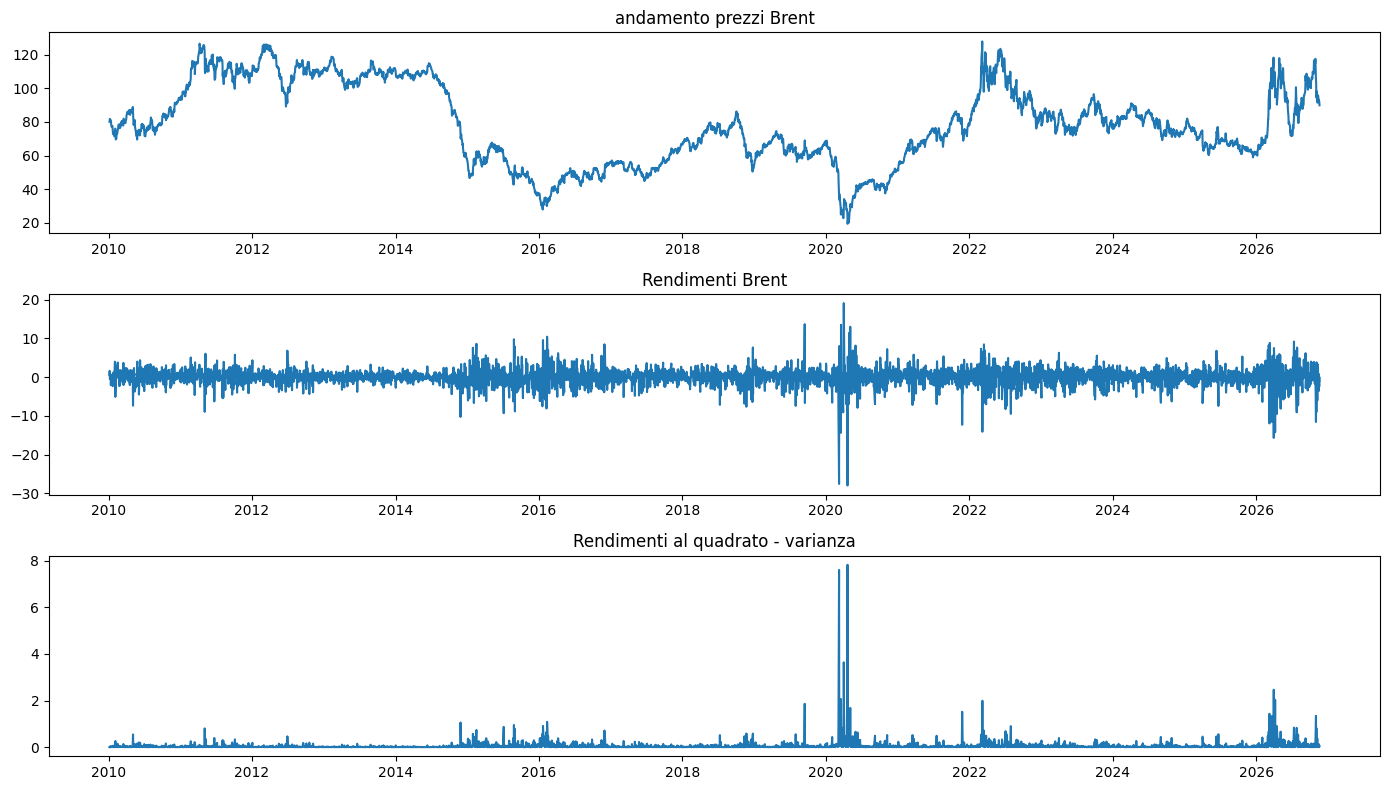

In [67]:
#1. Il petrolio Brent è stazionario? Motiva la risposta con i test appropriati.

#verifichiamo prima di tutta la stazionarietà visivamente con un grafico dei prezzi e dei rendimenti
fig, axes = plt.subplots(3,1 ,figsize=(14,8))

axes[0].plot(prezzi.index, prezzi)
axes[0].set_title("andamento prezzi Brent")
axes[1].plot(rendimenti.index, rendimenti*100)
axes[1].set_title("Rendimenti Brent")
axes[2].plot(rendimenti.index, rendimenti**2*100)
axes[2].set_title("Rendimenti al quadrato - varianza")

plt.tight_layout()



In [68]:
#verifichiamo la stazionarietà nei livelli, ovvero nei prezzi, con il test di Dickey-Fuller aumentato (ADF)
from statsmodels.tsa.stattools import adfuller
adf_test = adfuller(prezzi['BZ=F'])
print(f"ADF p_value: {adf_test[1]}")

ADF p_value: 0.1962962982730424


Il p-value del test ADF è uguale a 0.1920. Questo significa che non possiamo scartare l'ipotesi nulla di "non-stazionarietà" del test in nessuno dei casi statistici più usati (90, 95 e 99%)

In [69]:
#testiamo dunque la stazionarietà dei rendimenti logaritmici del petrolio Brent con il test di Dickey-Fuller aumentato (ADF)
adf_test_rendimenti = adfuller(rendimenti)
print(f"ADF p-value: {adf_test_rendimenti[1]}")

ADF p-value: 5.572339721809655e-24


In questo caso troviamo un p_value minore dei valori critici e possiamo dunque rifiutare l'ipotesi nulla di non stazionarità e dire che abbiamo evidenze di stazionarità della serie dei rendimenti.

In [70]:
#per essere certi della stazionarità dei rendimenti possiamo fare il test KPSS (Kwiatkowski-Phillips-Schmidt-Shin), il quale ha come ipotesi nulla la stazionarietà della serie. Se il p-value è maggiore di 0.05, non possiamo rifiutare l'ipotesi nulla e quindi possiamo concludere che la serie è stazionaria.
from statsmodels.tsa.stattools import kpss
kpss_test = kpss(rendimenti, regression='c')
print(f"KPSS Statistic: {kpss_test[1]}")

KPSS Statistic: 0.1


Anche il test KPSS ci fornisce prove di stazionarità della serie dei rendimenti del Brent.

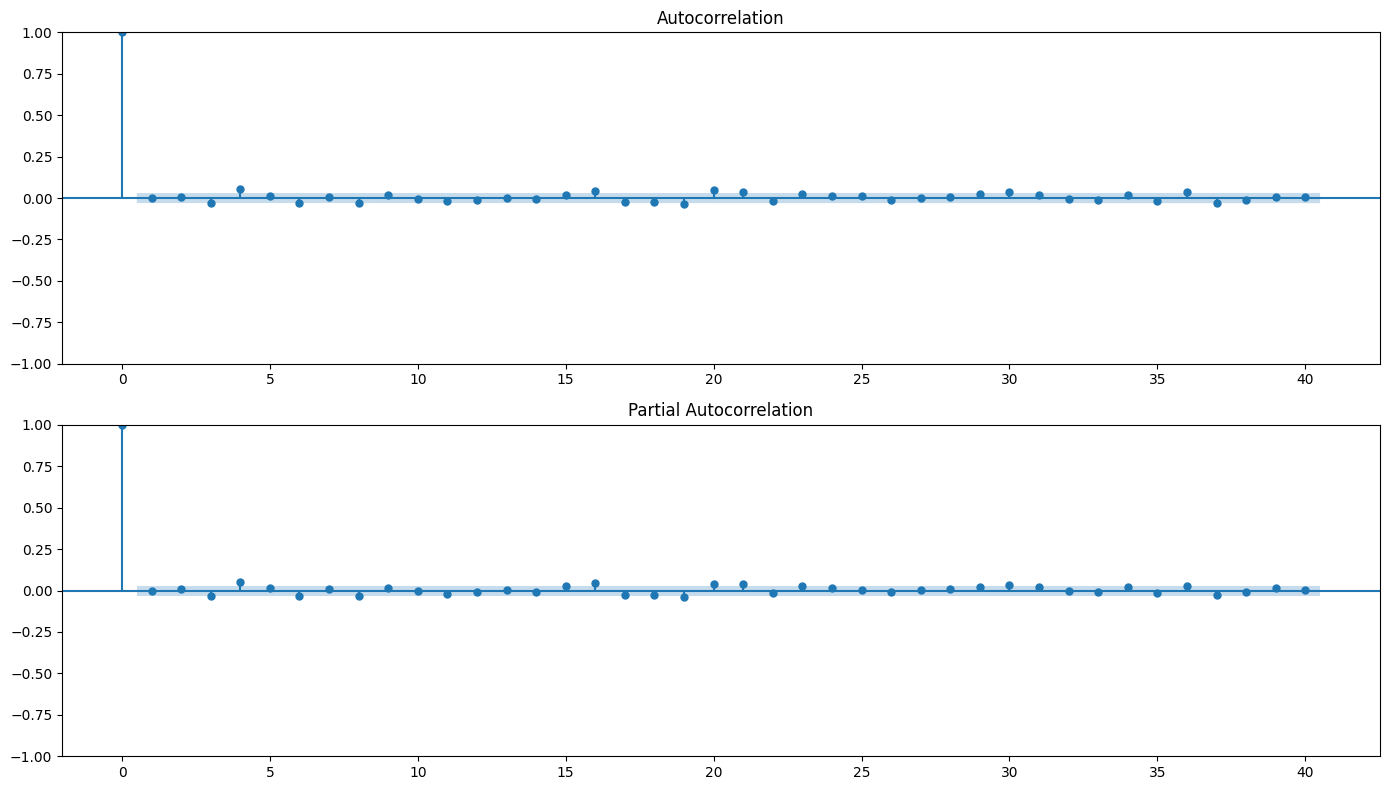

In [71]:
#Possiamo anche vedere la stazionarietà dei rendimenti con un grafico della funzione di autocorrelazione (ACF) e della funzione di autocorrelazione parziale (PACF)

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(2,1 ,figsize=(14,8))
plot_acf(rendimenti, ax=axes[0], lags=40)
plot_pacf(rendimenti, ax=axes[1], lags=40)
plt.tight_layout()

**2. C'è autocorrelazione nella media e nella varianza dei rendimenti? Quali modelli suggeriscono i dati?**

 Dal grafico ACF e PACF dei rendimenti (escludendo il lag 0, che vale sempre 1 per definizione) l’autocorrelazione nella media risulta molto debole. Quasi tutte le barre rientrano nella banda di confidenza al 95% (circa ±0.03). L’eccezione più evidente è il lag 4, con un’autocorrelazione di circa 0.05; alcuni altri lag sfiorano la banda, ma con 40 lag testati è atteso che un paio la superino per puro caso. ACF e PACF hanno un andamento quasi identico, segno che non c’è una struttura AR o MA marcata: i rendimenti del Brent sono vicini a un rumore bianco nella media, cioè la loro direzione è difficilmente prevedibile dal passato. Questa debole dipendenza suggerisce al più un modello ARMA di ordine basso, da verificare con i criteri informativi.

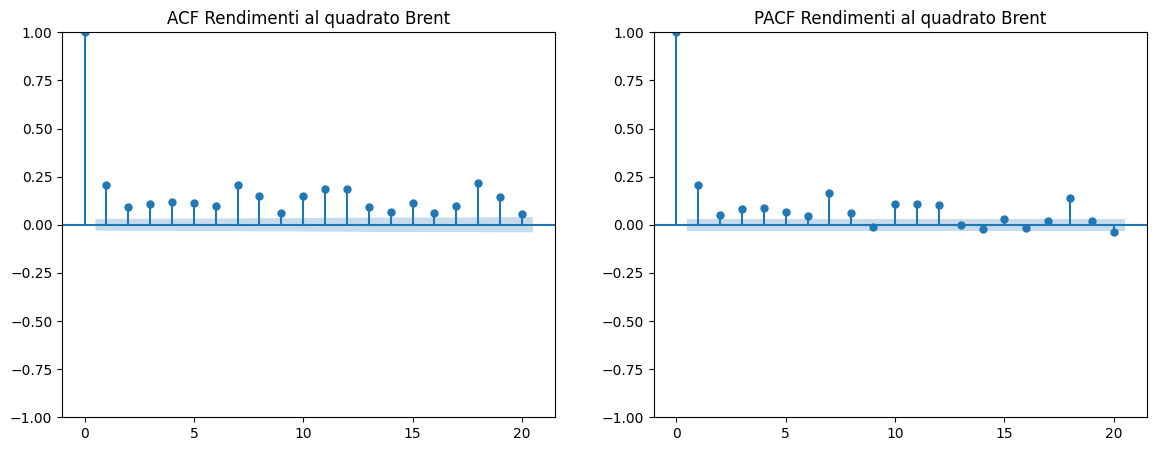

In [72]:
#Per capire se abbiamo anche autocorrelazione nella varianza possiamo fare gli stessi grafici ACF e PACF ma sui rendimenti al quadrato, in una serie stazionaria, l'ACF dovrebbe decrescere rapidamente verso zero, mentre la PACF dovrebbe mostrare un picco significativo al primo lag e poi decrescere rapidamente.fig, axes = plt.subplots(1, 2, figsize=(14,5))
fig, axes = plt.subplots(1, 2, figsize=(14,5))
plot_acf(rendimenti**2, lags=20, ax=axes[0], title="ACF Rendimenti al quadrato Brent")
plot_pacf(rendimenti**2, lags=20, ax=axes[1], title="PACF Rendimenti al quadrato Brent")
plt.show()

I grafici mostrano che vi sono prove di una forte autocorrelazione nella varianza, inquanto i lag rimangono significativi anche dopo il primo. Questo sarebbe inidzio della presenza di volatility clustering che potremo poi verificare.

In [73]:
#verifichiamo formalmente quanto abbiamo visto dai grafici usando il test di Ljung-Box, che ha come ipotesi nulla l'assenza di autocorrelazione. Se il p-value è maggiore di 0.05, non possiamo rifiutare l'ipotesi nulla e quindi possiamo concludere che la serie non ha autocorrelazione.
from statsmodels.stats.diagnostic import acorr_ljungbox
ljung_box_test_rend = acorr_ljungbox(rendimenti, lags=10)
print(ljung_box_test_rend)
ljung_box_test_rend2 = acorr_ljungbox(rendimenti**2, lags=10)
print(ljung_box_test_rend2)

      lb_stat  lb_pvalue
1    0.007896   0.929194
2    0.193572   0.907750
3    4.603128   0.203274
4   16.352087   0.002581
5   17.308537   0.003950
6   21.275523   0.001637
7   21.415378   0.003202
8   25.483655   0.001287
9   26.847074   0.001483
10  27.114218   0.002498
       lb_stat      lb_pvalue
1   177.325683   1.859328e-40
2   212.299736   7.937761e-47
3   259.954822   4.598093e-56
4   321.214820   2.867803e-68
5   375.298222   6.235582e-79
6   414.149852   2.534672e-86
7   591.657034  1.524069e-123
8   683.484656  2.570135e-142
9   699.550543  8.639772e-145
10  796.004896  1.490872e-164


I test confermano quanto abbiamo ipotizzato in precdenza dai grafici ACF e PACF.

**3.Stima il modello ARMA ottimale. I coefficienti sono significativi? Il modello è adeguato?**

In [74]:
#Utlizzando AIC come metodo di selezione del modello per essere parsimoniosi nella selezione dei parametri.
from statsmodels.tsa.arima.model import ARIMA
AIC = np.inf
for p in range(4):
    for q in range(4):
        modello_ARMA_migliore = ARIMA(rendimenti, order = ( p, 0, q)).fit()
        if (modello_ARMA_migliore.aic < AIC):
            AIC = modello_ARMA_migliore.aic
            parametri = (p,0,q)
print(parametri)

(2, 0, 3)


**Il modello migliore stimato è un ARIMA(3,0,2).**
Vediamo ora di commentare i risultati del modello.

In [75]:
modello_ARMA_migliore_AIC = ARIMA(rendimenti, order = (3,0,2)).fit()

summary = modello_ARMA_migliore_AIC.summary()
print(summary)

                               SARIMAX Results                                
Dep. Variable:                   BZ=F   No. Observations:                 4216
Model:                 ARIMA(3, 0, 2)   Log Likelihood                9827.319
Date:                Sun, 22 Nov 2026   AIC                         -19640.637
Time:                        17:43:54   BIC                         -19596.211
Sample:                             0   HQIC                        -19624.931
                               - 4216                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.229e-05      0.000      0.061      0.952      -0.001       0.001
ar.L1         -0.6552      0.086     -7.626      0.000      -0.824      -0.487
ar.L2         -0.7976      0.088     -9.016      0.0

Il criterio AIC seleziona un ARMA(3,2). Dal summary del modello stimato possiamo leggere che:

- const = 0.000018, p = 0.961. Non significativa: il rendimento medio giornaliero è statisticamente zero.
- I coefficienti AR e MA sono tutti significativi al 95% (p-value < 0.05), mentre al 99% ar.L3 non è significativo (p = 0.024). La significatività individuale va però letta con cautela: i coefficienti AR e MA sono quasi uguali in valore assoluto e di segno opposto (ar.L1 = −1.173 vs ma.L1 = 1.175; ar.L2 = −0.765 vs ma.L2 = 0.782). Le radici complesse dei due polinomi quasi coincidono (−0.78 ± 0.87i e −0.75 ± 0.85i) e si annullano in gran parte: il modello usa 5 parametri e una struttura numericamente instabile per catturare una debole autocorrelazione dei rendimenti.
- sigma2 = 0.0006: deviazione standard giornaliera dei residui di circa il 2.4%.
- Ljung-Box (L1), Prob(Q) = 0.98. Non rifiutiamo H0: non si rileva autocorrelazione significativa nei residui al lag 1.
- Heteroskedasticity H = 1.93, Prob(H) = 0.00. Rifiutiamo H0: la varianza dei residui non è costante nel tempo.
- Jarque-Bera = 33926, Prob(JB) = 0.00. Rifiutiamo la normalità dei residui.
     Skew −0.96: le cadute sono più violente dei rialzi.
     Kurtosis 16.76 contro 3 di una normale: code molto pesanti.

Data la possibile sovraparametrizzazione, confrontiamo il risultato con il criterio BIC, più severo nel penalizzare il numero di parametri.-

In [76]:
#BIC
from statsmodels.tsa.arima.model import ARIMA
BIC = np.inf
for p in range(4):
    for q in range(4):
        modello_ARMA_migliore_BIC = ARIMA(rendimenti, order = ( p, 0, q)).fit()
        if (modello_ARMA_migliore_BIC.bic < BIC):
            BIC = modello_ARMA_migliore_BIC.bic
            parametri = (p,0,q)
print(parametri)

(0, 0, 0)


In [77]:
modello_ARMA_migliore_BIC = ARIMA(rendimenti, order = (0,0,0)).fit()

summary = modello_ARMA_migliore_BIC.summary()
print(summary)

                               SARIMAX Results                                
Dep. Variable:                   BZ=F   No. Observations:                 4216
Model:                          ARIMA   Log Likelihood                9823.621
Date:                Sun, 22 Nov 2026   AIC                         -19643.241
Time:                        17:44:24   BIC                         -19630.548
Sample:                             0   HQIC                        -19638.754
                               - 4216                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.244e-05      0.000      0.060      0.952      -0.001       0.001
sigma2         0.0006   4.35e-06    127.407      0.000       0.001       0.001
Ljung-Box (L1) (Q):                   0.01   Jarque-

Il criterio BIC seleziona un ARMA(0,0), cioè un modello composto dalla sola costante. Dal summary del modello stimato possiamo leggere che:

- const = 0.0000189, p = 0.960. Non significativa: il rendimento medio giornaliero è statisticamente zero.
- sigma2 = 0.0006: la varianza dei residui è praticamente identica a quella dell’ARMA(3,2). I 5 parametri aggiuntivi del modello AIC riducono l’errore in misura minima.
- Ljung-Box (L1), Prob(Q) = 0.93. Non rifiutiamo H0: non si rileva autocorrelazione significativa nei residui al lag 1.
- Heteroskedasticity H = 1.95, Prob(H) = 0.00. Rifiutiamo H0: la varianza dei residui non è costante nel tempo.
- Jarque-Bera = 36760, Prob(JB) = 0.00. Rifiutiamo la normalità dei residui.
     Skew −0.97: le cadute sono più violente dei rialzi.
     Kurtosis 17.34 contro 3 di una normale: code molto pesanti.

Confronto tra i criteri. L’ARMA(3,2) ha una log-likelihood più alta di circa 11 punti (9833.7 contro 9822.8) con 5 parametri in più. L’AIC, che penalizza ogni parametro con 2 punti, preferisce l’ARMA(3,2) (−19653.5 contro −19641.6). Il BIC, che lo penalizza con ln(4216) ≈ 8.3 punti, preferisce l’ARMA(0,0) (−19628.9 contro −19609.0). Poiché il Ljung-Box del summary verifica solo il lag 1, per scegliere tra i due modelli testiamo l’autocorrelazione dei residui fino al lag 10.

In [78]:
lb_resid_AIC = acorr_ljungbox(modello_ARMA_migliore_AIC.resid, lags=10)
lb_resid_BIC = acorr_ljungbox(modello_ARMA_migliore_BIC.resid, lags=10)

print("Ljung-Box residui ARMA(3,2) - AIC")
print(lb_resid_AIC)
print("\nLjung-Box residui ARMA(0,0) - BIC")
print(lb_resid_BIC)

Ljung-Box residui ARMA(3,2) - AIC
      lb_stat  lb_pvalue
1    0.006998   0.933332
2    1.216528   0.544295
3    1.879982   0.597686
4    6.427782   0.169398
5    6.998291   0.220767
6    7.748855   0.257086
7    7.761491   0.354095
8   14.393967   0.072057
9   17.770942   0.037926
10  18.090519   0.053456

Ljung-Box residui ARMA(0,0) - BIC
      lb_stat  lb_pvalue
1    0.007896   0.929194
2    0.193572   0.907750
3    4.603128   0.203274
4   16.352087   0.002581
5   17.308537   0.003950
6   21.275523   0.001637
7   21.415378   0.003202
8   25.483655   0.001287
9   26.847074   0.001483
10  27.114218   0.002498


**Ljung-Box sui residui fino al lag 10**
H0: non c’è autocorrelazione nei residui fino al lag k
H1: c’è autocorrelazione significativa in almeno un lag fino a k

- ARMA(3,2): non rifiutiamo H0 per nessun lag (p-value compresi tra 0.45 e 0.98). I residui non presentano autocorrelazione: il modello cattura correttamente la dinamica della media.
- ARMA(0,0): non rifiutiamo H0 fino al lag 3 (p-value tra 0.21 e 0.93), ma la rifiutiamo dal lag 4 in poi (p-value tra 0.001 e 0.004). La statistica passa da 4.6 a 16.1 tra il lag 3 e il lag 4, segnalando una autocorrelazione dei rendimenti concentrata al lag 4 (circa 0.05 in valore assoluto). Il modello con la sola costante non riesce a catturarla.

**Scelta del modello**. Scegliamo l’ARMA(3,2): è l’unico dei due modelli adeguato per la media, perché i suoi residui sono privi di autocorrelazione. L’ARMA(0,0), pur più parsimonioso, lascia nei residui una struttura statisticamente significativa. La scelta ha però due limiti. Primo, l’autocorrelazione catturata è molto debole e spiega una quota trascurabile della varianza: la significatività dipende in buona parte dall’ampiezza del campione (4.216 osservazioni), quindi la prevedibilità della media del Brent resta economicamente minima. Secondo, il modello è sovraparametrizzato, con radici AR e MA che quasi si annullano, e potrebbe risultare instabile se stimato su campioni diversi.

**Il modello è adeguato?** Per la media sì. Non lo è per la varianza e la distribuzione: entrambi i modelli mostrano eteroschedasticità (H ≈ 1.9, p = 0.00), confermata dal Ljung-Box sui rendimenti al quadrato (p-value ≈ 0 a tutti i lag), e residui fortemente non normali (curtosi ≈ 17). La dinamica rilevante del Brent sta nella volatilità: per modellarla stimiamo un GARCH(1,1).

**4.Stima un GARCH(1,1). Interpreta i parametri e verifica che il modello sia adeguato.**


In [79]:
%pip install arch

In [80]:
from arch import arch_model

garch_model = arch_model(rendimenti*100,vol='Garch', p=1, q=1, dist = 'normal').fit(disp='off') 
print(garch_model.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   BZ=F   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -8876.86
Distribution:                  Normal   AIC:                           17761.7
Method:            Maximum Likelihood   BIC:                           17787.1
                                        No. Observations:                 4216
Date:                Sun, Nov 22 2026   Df Residuals:                     4215
Time:                        17:44:28   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu             0.0164  2.806e-02      0.586      0.558 

In [81]:
omega = garch_model.params["omega"]
alpha = garch_model.params["alpha[1]"]
beta  = garch_model.params["beta[1]"]

persistenza       = alpha + beta
var_lungo_periodo = omega / (1 - persistenza)
vol_lungo_annua   = np.sqrt(var_lungo_periodo) * np.sqrt(252)

print(f"Varianza di lungo periodo: {var_lungo_periodo:.2f} %^2")
print(f"Volatilità giornaliera di lungo periodo: {np.sqrt(var_lungo_periodo):.2f} %")
print(f"Volatilità annualizzata di lungo periodo: {vol_lungo_annua:.2f} %")

Varianza di lungo periodo: 7.40 %^2
Volatilità giornaliera di lungo periodo: 2.72 %
Volatilità annualizzata di lungo periodo: 43.19 %


Il rendimento medio (mu = 0.017%, p = 0.55) non è significativo, in linea con la costante non significativa dell’ARMA (p = 0.96): entrambi i modelli indicano che il rendimento medio giornaliero del Brent è statisticamente nullo.
Il GARCH è stimato con media costante e non incorpora la debole autocorrelazione individuata dall’ARMA(3,2). Data la sua entità trascurabile, l’impatto sulla stima della volatilità è minimo, come verificheremo con il Ljung-Box sui residui standardizzati.

Tutti i parametri della varianza sono positivi e significativi:

- omega = 0.091 (p = 0.004): componente costante della varianza.
- alpha = 0.104 (p < 0.001): effetto shock. Circa il 10% dello shock al quadrato del giorno precedente si trasmette alla varianza di oggi. È un valore elevato, tipico di una commodity che reagisce con forza alle notizie: ad esempio, un calo del 5% partendo dalla volatilità media fa salire la volatilità annualizzata da circa il 43% a circa il 48% in un solo giorno.
- beta = 0.884 (p < 0.001): effetto persistenza. La volatilità di oggi dipende in larga parte da quella di ieri.

La persistenza α + β = 0.988 è inferiore a 1, quindi il processo è stazionario in varianza: dopo uno shock la volatilità ritorna verso il livello di lungo periodo, pari a circa 2.7% giornaliero (≈ 43% annualizzato). Il ritorno è però lento: l’half-life di uno shock è di circa 56 giorni di borsa. Questo spiega i lunghi periodi di alta volatilità osservati nel 2020 e nel 2022. Data la vicinanza della persistenza a 1, la volatilità di lungo periodo è stimata con una certa imprecisione e va letta come ordine di grandezza.

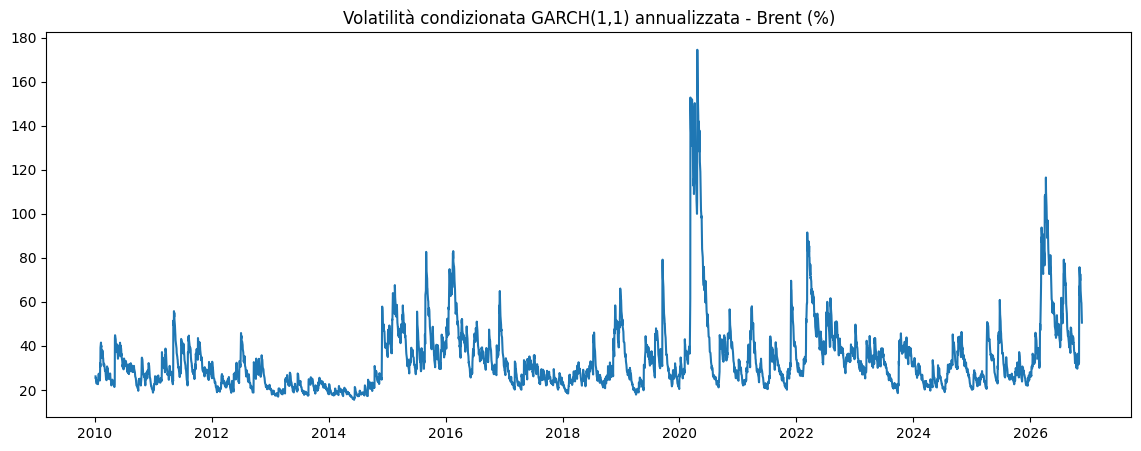

In [82]:
plt.figure(figsize=(14,5))
plt.plot(garch_model.conditional_volatility.index, garch_model.conditional_volatility*np.sqrt(252))
plt.title("Volatilità condizionata GARCH(1,1) annualizzata - Brent (%)")
plt.show()

**Diagnostica**

Residui standardizzati = residui / volatilità condizionata. Se il GARCH è adeguato, devono essere privi di autocorrelazione sia nei livelli sia nei quadrati.

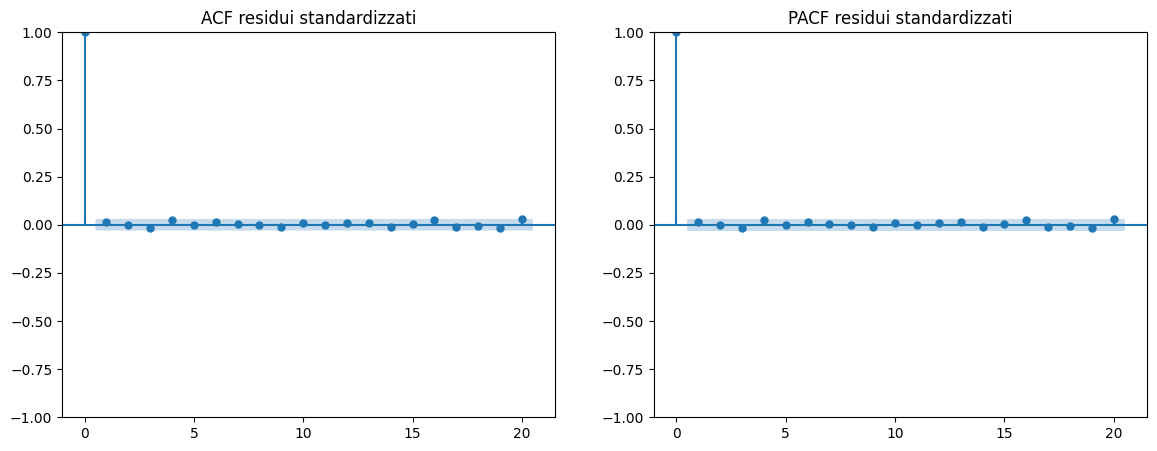

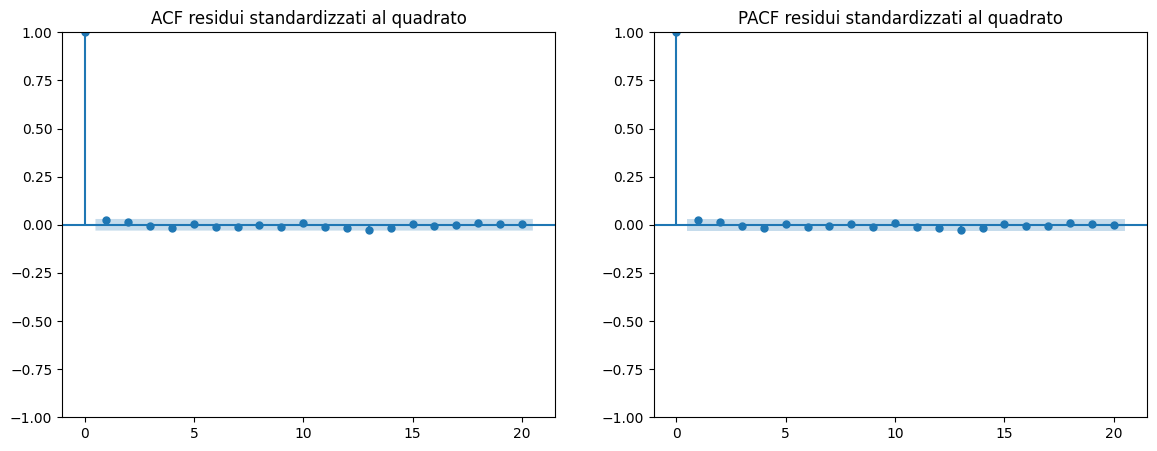

In [83]:
residuo_std = garch_model.resid / garch_model.conditional_volatility

fig, axes = plt.subplots(1, 2, figsize=(14,5))
plot_acf(residuo_std, lags=20, ax=axes[0], title="ACF residui standardizzati")
plot_pacf(residuo_std, lags=20, ax=axes[1], title="PACF residui standardizzati")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14,5))
plot_acf(residuo_std**2, lags=20, ax=axes[0], title="ACF residui standardizzati al quadrato")
plot_pacf(residuo_std**2, lags=20, ax=axes[1], title="PACF residui standardizzati al quadrato")
plt.show()

**Test Ljung-Box sui residui standardizzati**

- H0: non c’è autocorrelazione fino al lag k
- H1: c’è autocorrelazione significativa in almeno un lag fino a k

In [84]:
lb_std  = acorr_ljungbox(residuo_std, lags=10)
lb_std2 = acorr_ljungbox(residuo_std**2, lags=10)

print("Ljung-Box residui standardizzati")
print(lb_std)
print("\nLjung-Box residui standardizzati al quadrato")
print(lb_std2)

Ljung-Box residui standardizzati
     lb_stat  lb_pvalue
1   0.681217   0.409168
2   0.684379   0.710213
3   2.184477   0.535012
4   4.882346   0.299584
5   4.882409   0.430399
6   5.581779   0.471628
7   5.660550   0.579896
8   5.666567   0.684524
9   6.092169   0.730659
10  6.627114   0.760116

Ljung-Box residui standardizzati al quadrato
     lb_stat  lb_pvalue
1   3.125814   0.077061
2   3.949798   0.138775
3   4.215320   0.239133
4   5.544369   0.235857
5   5.617188   0.345267
6   6.439519   0.375795
7   6.798967   0.450107
8   6.804293   0.557888
9   7.634998   0.571306
10  7.972097   0.631563


Test ARCH sui residui standardizzati
- H0: non c’è eteroschedasticità, la varianza è costante
- H1: c’è eteroschedasticità, la varianza cambia nel tempo

In [85]:
from statsmodels.stats.diagnostic import het_arch
arch_std = het_arch(residuo_std, nlags=10)
print(f"p-value test ARCH sui residui standardizzati: {arch_std[1]:.4f}")

p-value test ARCH sui residui standardizzati: 0.6402


Diagnostica del GARCH(1,1)

- Ljung-Box sui residui standardizzati al quadrato: p-value compresi tra 0.08 e 0.63, tutti superiori a 0.05. Non rifiutiamo H0: non si rileva autocorrelazione residua nella varianza. Il confronto con i rendimenti al quadrato (p-value ≈ 10⁻¹⁶⁴) mostra che il GARCH ha catturato il clustering di volatilità. Il p-value al lag 1 (0.077) è il più vicino alla soglia, ma resta non significativo.
- Test ARCH sui residui standardizzati: p = 0.64. Non rifiutiamo H0: non resta eteroschedasticità condizionata.
- Ljung-Box sui residui standardizzati: p-value compresi tra 0.30 e 0.76. Non si rileva autocorrelazione nemmeno nella media. L’autocorrelazione al lag 4 emersa nell’analisi ARMA (p ≈ 0.003) non è più presente una volta tenuto conto della volatilità variabile: era verosimilmente indotta dall’eteroschedasticità, che distorce il test di Ljung-Box sui rendimenti grezzi. Questo giustifica la scelta di stimare il GARCH con media costante.

Conclusione. Il GARCH(1,1) è adeguato: i residui standardizzati non presentano autocorrelazione né nella media né nella varianza. Il modello non corregge però le code pesanti della distribuzione, perché assume shock normali: questo aspetto sarà rilevante nella costruzione del VAR al 99%.

**5. Costruisci un VAR dinamico al 99% con la volatilità GARCH. Confrontalo con il VAR statico e con il VAR EWMA. Quale produce meno violazioni?**

VARₜ = μ + z₀.₀₁ · σₜ, con z₀.₀₁ = −2.326

La differenza è metodo di stima della volatilità:
- STATICO: una sola σ, deviazione standard di tutto il campione; la volatilità è costante
- EWMA: media mobile esponenziale dei rendimenti al quadrato, λ = 0.94; la volatilità cambia, e i giorni recenti pesano di più
- GARCH: σ²ₜ = ω + α·ε²ₜ₋₁ + β·σ²ₜ₋₁, con parametri stimati; la volatilità cambia e tende a tornare a un livello di lungo periodo

In [86]:
#VAR statico, EWMA & GARCH 
from scipy.stats import norm

mu = rendimenti['BZ=F'].mean()
z  = norm.ppf(0.01)          # -2.326

# VAR statico
sigma = rendimenti['BZ=F'].std()
var_statico = mu + z * sigma

# Volatilità GARCH ed EWMA
LAMBDA    = 0.94
vol_garch = garch_model.conditional_volatility / 100
vol_ewma  = rendimenti['BZ=F'].ewm(alpha = 1 - LAMBDA).std().shift(1)   # shift: uso solo informazioni fino a ieri

print("La volatilità media annualizzata è di")
print(f"Statica: {sigma * np.sqrt(252)*100:.2f} %")
print(f"GARCH:   {vol_garch.mean()* np.sqrt(252)*100:.2f} %")
print(f"EWMA:    {vol_ewma.mean()* np.sqrt(252)*100:.2f} %")

print("\nLa volatilità giornaliera massima è di")
print(f"GARCH: {vol_garch.max()*100:.2f} %")
print(f"EWMA:  {vol_ewma.max()*100:.2f} %")

print("\nLa volatilità giornaliera minima è di")
print(f"GARCH: {vol_garch.min()*100:.2f} %")
print(f"EWMA:  {vol_ewma.min()*100:.2f} %")

La volatilità media annualizzata è di
Statica: 37.37 %
GARCH:   34.14 %
EWMA:    32.93 %

La volatilità giornaliera massima è di
GARCH: 10.99 %
EWMA:  9.53 %

La volatilità giornaliera minima è di
GARCH: 0.98 %
EWMA:  0.58 %


In [87]:
var_dinamico_garch = mu + z * vol_garch
var_dinamico_ewma  = mu + z * vol_ewma

df_var = pd.DataFrame({
    "rendimenti":  rendimenti['BZ=F'],
    "var_statico": var_statico,
    "var_garch":   var_dinamico_garch,
    "var_ewma":    var_dinamico_ewma
}).dropna()

print(f"VAR statico al 99%: {var_statico*100:.2f} %")
print(df_var.tail())

VAR statico al 99%: -5.47 %
            rendimenti  var_statico  var_garch  var_ewma
Date                                                    
2026-11-16   -0.036120    -0.054743  -0.087845 -0.085922
2026-11-17    0.007544    -0.054743  -0.087229 -0.085236
2026-11-18   -0.012859    -0.054743  -0.082482 -0.082982
2026-11-19    0.000326    -0.054743  -0.078461 -0.080571
2026-11-20   -0.022317    -0.054743  -0.074086 -0.078185


In [88]:
viol_statico = (df_var["rendimenti"] < df_var["var_statico"]).sum()
viol_garch   = (df_var["rendimenti"] < df_var["var_garch"]).sum()
viol_ewma    = (df_var["rendimenti"] < df_var["var_ewma"]).sum()

n = len(df_var)
print(f"Giorni analizzati: {n}  |  violazioni attese al 99%: {0.01*n:.0f} (1%)\n")
print(f"VAR statico: {viol_statico} violazioni ({viol_statico/n*100:.2f} %)")
print(f"VAR GARCH:   {viol_garch} violazioni ({viol_garch/n*100:.2f} %)")
print(f"VAR EWMA:    {viol_ewma} violazioni ({viol_ewma/n*100:.2f} %)")

Giorni analizzati: 4214  |  violazioni attese al 99%: 42 (1%)

VAR statico: 74 violazioni (1.76 %)
VAR GARCH:   77 violazioni (1.83 %)
VAR EWMA:    106 violazioni (2.52 %)


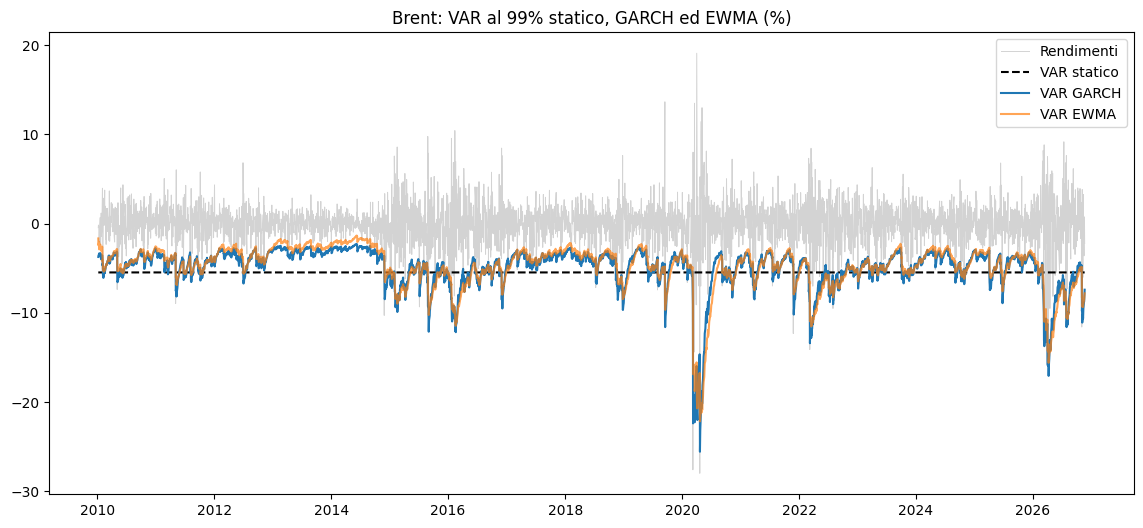

In [89]:
plt.figure(figsize=(14,6))
plt.plot(df_var.index, df_var["rendimenti"]*100, label="Rendimenti", color="lightgray", linewidth=0.7)
plt.plot(df_var.index, df_var["var_statico"]*100, label="VAR statico", color="black", linestyle="--")
plt.plot(df_var.index, df_var["var_garch"]*100, label="VAR GARCH")
plt.plot(df_var.index, df_var["var_ewma"]*100, label="VAR EWMA", alpha=0.7)
plt.title("Brent: VAR al 99% statico, GARCH ed EWMA (%)")
plt.legend()
plt.show()

In [90]:
viol = pd.DataFrame({
    "Statico": df_var["rendimenti"] < df_var["var_statico"],
    "GARCH":   df_var["rendimenti"] < df_var["var_garch"],
    "EWMA":    df_var["rendimenti"] < df_var["var_ewma"]
})

viol_anno = viol.groupby(viol.index.year).sum()
attese_anno = viol.groupby(viol.index.year).size() * 0.01

tabella = viol_anno.copy()
tabella["Attese"] = attese_anno.round(1)
print(tabella)

      Statico  GARCH  EWMA  Attese
Date                              
2010        1      3     4     2.5
2011        2      6     7     2.4
2012        0      3     8     2.4
2013        0      2     4     2.4
2014        1      4     9     2.5
2015        7      5     6     2.5
2016        5      3     3     2.5
2017        0      4     5     2.5
2018        6      7    10     2.5
2019        2      3     6     2.5
2020       16      6     6     2.5
2021        4      4     7     2.5
2022       10      5     5     2.5
2023        1      5     5     2.5
2024        2      6     7     2.5
2025        4      4     5     2.5
2026       13      7     9     2.2


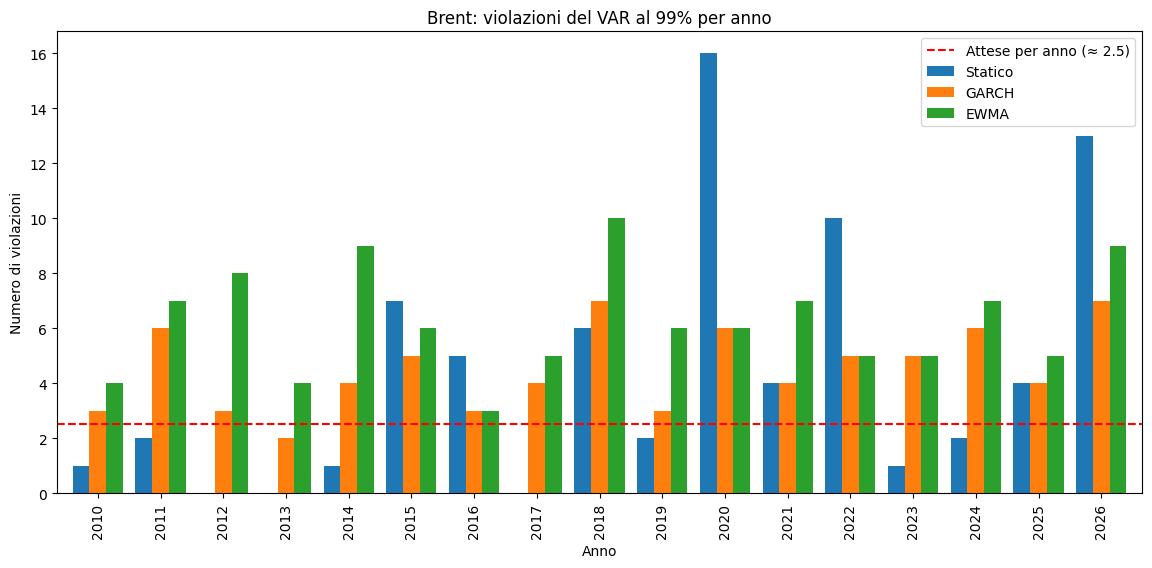

In [91]:
viol_anno.plot(kind="bar", figsize=(14,6), width=0.8)
plt.axhline(0.01 * 252, color="red", linestyle="--", label="Attese per anno (≈ 2.5)")
plt.title("Brent: violazioni del VAR al 99% per anno")
plt.xlabel("Anno")
plt.ylabel("Numero di violazioni")
plt.legend()
plt.show()

**Confronto delle violazioni**

Su 4.214 giorni analizzati ci attendiamo circa 42 violazioni al 99% (1%), con un intervallo compatibile con il caso di circa 29–55 (± 2 deviazioni standard di una binomiale). Il VAR statico registra 74 violazioni (1.76%), il VAR GARCH 77 (1.83%) e il VAR EWMA 106 (2.52%). Tutti e tre i modelli superano il numero atteso e quindi sottostimano il rischio del Brent.

Il VAR statico produce il numero minore di violazioni, ma la differenza rispetto al GARCH (3 violazioni) è inferiore a una deviazione standard e non è statisticamente rilevante. Soprattutto, le violazioni del VAR statico sono concentrate nel tempo: nessuna violazione nel 2012, 2013 e 2017, ma 16 nel 2020, 10 nel 2022 e 13 nel 2026. Basato su una volatilità costante, il VAR statico è troppo prudente nei periodi calmi e insufficiente proprio nelle crisi, quando le perdite sono più gravi. Il totale apparentemente accettabile deriva dalla compensazione tra questi due errori.

Il VAR GARCH distribuisce le violazioni in modo molto più uniforme (tra 2 e 7 per anno, 6 nel 2020 contro le 16 dello statico): segue correttamente l’evoluzione della volatilità nel tempo. Supera però le violazioni attese quasi ogni anno. È un errore sistematico di livello, dovuto all’uso del quantile della normale (−2.326) su rendimenti con code molto pesanti (curtosi ≈ 17): il modello cattura la dinamica della volatilità, ma non la frequenza degli eventi estremi.

Il VAR EWMA è il meno accurato (106 violazioni, 2.5 volte quelle attese). A differenza del GARCH non include una componente di varianza di lungo periodo: dopo periodi tranquilli la volatilità stimata scende troppo e il VAR risulta troppo stretto di fronte a shock improvvisi (8, 9 e 10 violazioni nel 2012, 2014 e 2018, contro 3, 4 e 7 del GARCH). Inoltre, con λ = 0.94 reagisce più lentamente agli shock rispetto al GARCH stimato (peso sull’ultimo shock del 6% contro il 10.4%).

**Conclusione.** Il VAR statico produce il minor numero di violazioni, ma il VAR GARCH è il più affidabile: le sue violazioni sono distribuite nel tempo e non si concentrano nelle crisi. Il suo eccesso di violazioni potrebbe essere ridotto sostituendo il quantile della normale con quello di una distribuzione a code pesanti, come la t di Student.

**6. Perché un Risk Manager preferirebbe il VAR dinamico per il petrolio Brent?**

1. La volatilità del Brent non è costante, e i dati lo dimostrano. Il VAR statico assume una volatilità fissa, ipotesi smentita da tutte le analisi svolte: il Ljung-Box sui rendimenti al quadrato rifiuta l’assenza di autocorrelazione con p-value dell’ordine di 10⁻¹⁶⁴, il test di eteroschedasticità indica una varianza dei residui quasi doppia nell’ultimo terzo del campione (H = 1.95) e il GARCH stima una persistenza di 0.988. La volatilità del Brent si muove a ondate (crollo del 2014-15, pandemia del 2020, invasione dell’Ucraina nel 2022), e un modello che la tratta come costante descrive un mercato che non esiste.

2. Il VAR dinamico protegge quando serve. Il VAR statico fallisce proprio nei momenti in cui il rischio si materializza: 16 violazioni nel 2020, 10 nel 2022 e 13 nel 2026, contro le 6, 5 e 7 del GARCH. Per un Risk Manager non conta solo quante volte il modello sbaglia, ma quando. Un VAR violato a ripetizione durante una crisi lascia l’istituzione esposta a perdite consecutive senza alcun segnale di allarme. Applicando il sistema a semaforo di Basilea (finestre di circa 250 giorni: 0-4 violazioni zona verde, 5-9 gialla, 10 o più rossa), il VAR statico finisce in zona rossa nel 2020, 2022 e 2026, mentre il VAR GARCH non raggiunge mai la zona rossa.

3. Il VAR dinamico usa il capitale in modo efficiente. Negli anni tranquilli il VAR statico è troppo prudente: nessuna violazione nel 2012, 2013 e 2017. Questo significa capitale immobilizzato a coprire un rischio che in quel momento non c’è, con costi opportunità e limiti di posizione inutilmente stretti. Il VAR dinamico si restringe quando il mercato è calmo e si allarga quando diventa turbolento, adattando le riserve al rischio effettivo.

4. Il VAR dinamico reagisce alle notizie. Il petrolio è esposto a shock improvvisi: decisioni OPEC+, tensioni geopolitiche, shock di domanda. Il GARCH stimato assegna il 10.4% di peso allo shock del giorno precedente: un singolo calo del 5% porta la volatilità annualizzata da circa il 43% al 48% il giorno successivo. Il VAR statico resterebbe identico qualunque cosa accada sul mercato. Con un’half-life di circa 56 giorni, il modello mantiene inoltre il VAR elevato per tutto il tempo in cui la turbolenza persiste, invece di dimenticarla subito.

5. Tra i modelli dinamici, il GARCH è preferibile all’EWMA. I parametri sono stimati sui dati invece che fissati a priori, e la componente di varianza di lungo periodo impedisce alla volatilità di scendere troppo nei periodi calmi. Il risultato è un numero di violazioni sensibilmente inferiore (77 contro 106).

I limiti da tenere presenti. Il VAR dinamico non risolve tutti i problemi. Tutti i modelli analizzati usano il quantile della normale e sottostimano gli eventi estremi di un asset con code pesanti come il Brent (curtosi ≈ 17), come mostrano le violazioni del GARCH superiori all’atteso quasi ogni anno. Inoltre l’analisi è in-sample. Un Risk Manager affiancherebbe quindi al VAR GARCH una distribuzione a code pesanti (ad esempio la t di Student), un backtest out-of-sample e stress test su scenari estremi come quello del 2020.

In sintesi: il VAR statico può sembrare accettabile guardando solo il totale delle violazioni, ma fallisce nelle crisi e spreca capitale nei periodi calmi. Il VAR dinamico GARCH segue il rischio effettivo del Brent giorno per giorno, ed è quindi lo strumento più adatto alla gestione del rischio su un asset volatile come il petrolio.